# Carga de los datos

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from utils import (AZUL, NARANJA, GRIS_TEXTO, GRIS_GRILLA, DIVERGENTE,
                   aplicar_estilo, hexbin_par, escala_comun, banda_por_hora)

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/bivariadas/'

# Paleta, colormaps y funciones de gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

In [3]:
df = pd.read_csv(PROCESSED + '/mediciones_limpias.csv')
df.head(5)

,station_id,target_hour_utc,horizonte_horas,obs_timestamp,fcst_target_timestamp,fcst_generated_at,obs_temp_c,fcst_temp_c,obs_heat_index_c,obs_rh_pct,...,categoria,hora_local,error_temp_c,abs_error_temp_c,error_rh_pct,abs_error_rh_pct,error_dewpoint_c,abs_error_dewpoint_c,error_windspeed_kmh,abs_error_windspeed_kmh
0,057CE,2026-10-19T17,6,2026-10-19 17:10:00+00:00,2026-10-19 17:00:00+00:00,2026-10-19 11:00:00+00:00,24.34,22.22,24.250812,54.431107,...,ok,12,-2.12,2.12,4.568893,4.568893,-0.671111,0.671111,3.994,3.994
1,BDWM4,2026-10-21T12,6,2026-10-21 12:32:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,-1.11,3.33,NaN,91.012237,...,ok,8,4.44,4.44,3.987763,3.987763,5.167778,5.167778,3.220,3.220
2,E7246,2026-10-21T12,6,2026-10-21 12:30:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,2.78,8.33,NaN,86.868260,...,intermitente,6,5.55,5.55,13.131740,13.131740,7.523333,7.523333,0.000,0.000
3,F3284,2026-10-21T12,6,2026-10-21 12:30:00+00:00,2026-10-21 12:00:00+00:00,2026-10-21 06:00:00+00:00,10.00,8.89,NaN,73.245166,...,intermitente,7,-1.11,1.11,-3.245166,3.245166,-1.541111,1.541111,9.660,9.660
4,ARD06,2026-10-19T17,6,2026-10-19 17:30:00+00:00,2026-10-19 17:00:00+00:00,2026-10-19 11:00:00+00:00,23.44,21.11,22.860360,39.094649,...,intermitente,12,-2.33,2.33,-1.094649,1.094649,-2.618889,2.618889,-1.548,1.548


In [4]:
print(df.columns)

Index(['station_id', 'target_hour_utc', 'horizonte_horas', 'obs_timestamp',
       'fcst_target_timestamp', 'fcst_generated_at', 'obs_temp_c',
       'fcst_temp_c', 'obs_heat_index_c', 'obs_rh_pct', 'fcst_rh_pct',
       'obs_wind_direction_d', 'obs_windspeed_kmh', 'fcst_windspeed_kmh',
       'obs_dewpoint_c', 'fcst_dewpoint_c', 'fcst_pop_pct', 'fecha_particion',
       'hora_particion', 'estado', 'timeZone', 'latitud', 'longitud',
       'elevation', 'red', 'categoria', 'hora_local', 'error_temp_c',
       'abs_error_temp_c', 'error_rh_pct', 'abs_error_rh_pct',
       'error_dewpoint_c', 'abs_error_dewpoint_c', 'error_windspeed_kmh',
       'abs_error_windspeed_kmh'],
      dtype='str')


# Limpieza de datos

`mediciones_limpias.csv` ya tiene los apóstrofos corregidos, los valores imposibles descartados (sección 1 de
`relaciones-bivariadas.ipynb`) y los atributos de estación. Lo que falta para poder hacer ACF/estacionariedad es específico
de series temporales:

1. **Regularizar el índice temporal** por estación (ahora mismo las filas de estaciones distintas vienen intercaladas y,
   dentro de cada estación, faltan horas enteras -no sólo valores vacíos en filas existentes).
2. **Detectar y entender los huecos** antes de decidir cómo tratarlos: no son todos iguales.
3. **Filtrar las estaciones** a un cohorte con intermitencia manejable para trabajar serie por serie.
4. **Corregir saltos horarios imposibles** (un atípico temporal, distinto de los outliers obs-vs-pronóstico ya filtrados).
5. **Imputar de forma acotada** (sólo huecos cortos) y dejar un flag de qué se imputó.
6. **Discretizar la dirección del viento** en sectores y codificar la hora de forma cíclica.

### 1. Ordenar y medir el rango temporal del proyecto

In [5]:
df['target_hour_utc'] = pd.to_datetime(df['target_hour_utc'], utc=True)
df = df.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

RANGO_COMPLETO = pd.date_range(df['target_hour_utc'].min(), df['target_hour_utc'].max(), freq='h')
print(f'Rango del proyecto: {RANGO_COMPLETO.min()} a {RANGO_COMPLETO.max()} ({len(RANGO_COMPLETO)} horas)')

Rango del proyecto: 2026-10-19 02:00:00+00:00 a 2026-11-02 21:00:00+00:00 (356 horas)


### 2. Cobertura y huecos por estación

Por estación: cuántas horas tiene sobre las {len(RANGO_COMPLETO)} posibles, y cuál es el hueco (sin ninguna fila) más largo.

In [6]:
def resumen_cobertura(g):
    huecos = g['target_hour_utc'].diff().dt.total_seconds().div(3600).dropna()
    return pd.Series({
        'n_horas': len(g),
        'cobertura_pct': 100 * len(g) / len(RANGO_COMPLETO),
        'hueco_max_h': huecos.max() if len(huecos) else np.nan,
    })

cobertura = df.groupby('station_id').apply(resumen_cobertura)
atributos_estacion = df.groupby('station_id')[['estado', 'timeZone', 'latitud', 'longitud', 'elevation', 'red', 'categoria']].first()
cobertura = cobertura.join(atributos_estacion)
cobertura['hueco_max_h'].describe()

count    498.000000
mean      43.345382
std       50.523150
min        5.000000
25%       11.000000
50%       11.000000
75%      120.000000
max      304.000000
Name: hueco_max_h, dtype: float64

El hueco máximo no crece de forma gradual: salta de ~11 h (mediana) a ~120 h (percentil 75). Es una distribución
bimodal, no un espectro continuo de intermitencia -conviene mirarla antes de elegir un umbral.

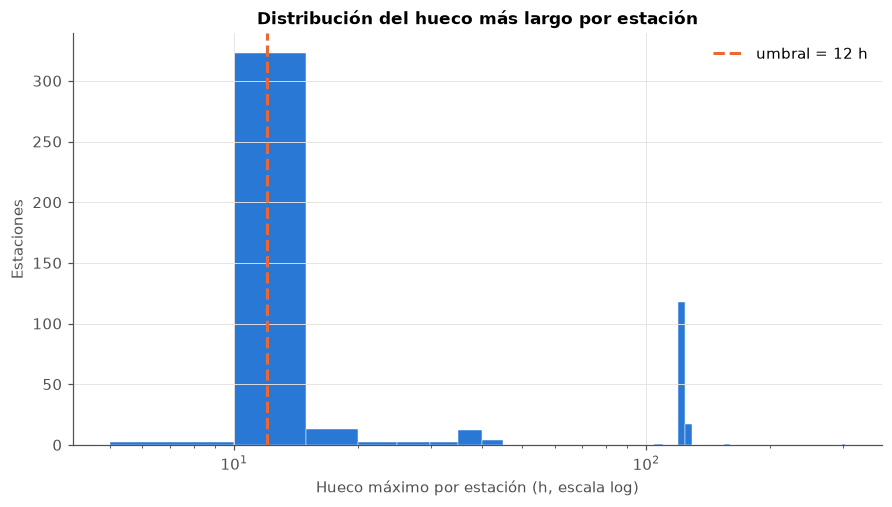

In [7]:
UMBRAL_HUECO = 12  # horas; separa el cluster de huecos "normales" (1-11 h) del salto a ~120 h

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(cobertura['hueco_max_h'], bins=60, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(UMBRAL_HUECO, color=NARANJA, lw=2, ls='--', label=f'umbral = {UMBRAL_HUECO} h')
ax.set(xscale='log', xlabel='Hueco máximo por estación (h, escala log)', ylabel='Estaciones',
       title='Distribución del hueco más largo por estación')
ax.legend(frameon=False)
figuras['12_huecos_por_estacion'] = fig
plt.show()

### 3. El grupo de huecos largos no es ruido aleatorio: es un corte compartido

Para las estaciones con un hueco mayor al umbral, ¿cuándo empieza y termina ese hueco? Si fuera intermitencia propia de cada
estación, las fechas estarían repartidas. Si en cambio se concentran en las mismas fechas, es un corte de la colección de
datos que afectó a varias estaciones a la vez.

In [8]:
def hueco_mas_largo(g):
    t = g['target_hour_utc'].reset_index(drop=True)
    d = t.diff().dt.total_seconds().div(3600)
    if d.max(skipna=True) is np.nan or d.max() <= UMBRAL_HUECO:
        return pd.Series({'inicio_hueco': pd.NaT, 'fin_hueco': pd.NaT, 'hueco_h': np.nan})
    idx = d.idxmax()
    return pd.Series({'inicio_hueco': t[idx - 1], 'fin_hueco': t[idx], 'hueco_h': d[idx]})

huecos_largos = df.groupby('station_id').apply(hueco_mas_largo).dropna()
print(f'{len(huecos_largos)} estaciones con un hueco mayor a {UMBRAL_HUECO} h')
print()
print('Fecha de inicio del hueco (agrupado por día):')
print(huecos_largos['inicio_hueco'].dt.floor('D').value_counts().sort_index())
print()
print('Redes de las estaciones cuyo hueco empieza el 22/10:')
afectadas_22 = huecos_largos[huecos_largos['inicio_hueco'].dt.floor('D') == pd.Timestamp('2026-10-22', tz='UTC')].index
print(cobertura.loc[afectadas_22, 'red'].value_counts())

174 estaciones con un hueco mayor a 12 h

Fecha de inicio del hueco (agrupado por día):
inicio_hueco
2026-10-19 00:00:00+00:00     10
2026-10-20 00:00:00+00:00      2
2026-10-21 00:00:00+00:00      3
2026-10-22 00:00:00+00:00    138
2026-10-25 00:00:00+00:00      1
2026-10-26 00:00:00+00:00      2
2026-10-29 00:00:00+00:00      2
2026-10-31 00:00:00+00:00      7
2026-11-01 00:00:00+00:00      9
Name: count, dtype: int64

Redes de las estaciones cuyo hueco empieza el 22/10:
red
RAWS           57
TG             20
APRSWXNET      18
ARDOT           5
SuperAWOS       5
ULM             5
MNDOT           5
TWDB            5
SAI             4
OTHER-MTR       3
NEDOR           3
IADOT           3
CENTERPOINT     2
MT-MESO         1
NGLO            1
WISCONET        1
Name: count, dtype: int64


Confirmado: la mayoría de los huecos largos (138 de 174) arrancan el **22/10** y terminan el **27/10** -un corte de
~5 días que afectó sobre todo a la red `RAWS`, además de una decena de redes chicas. No es una falla de sensores individuales,
es un problema de colección en una ventana puntual. Por eso no se debe "parchar" con imputación -la ventana del corte queda
documentada acá en vez de disimulada-, pero tampoco hay que descartar la estación entera sólo por haber estado del lado
equivocado de un apagón que no depende de ella: el hueco máximo de cada estación se vuelve a medir a continuación
**ignorando el tramo que coincide con esa ventana puntual**.

### 3bis. Separar el corte compartido de la intermitencia propia

El umbral de `UMBRAL_HUECO` no cambia: sigue siendo el que decide qué estación entra al cohorte. Lo que cambia es **qué se
mide** contra ese umbral -el hueco máximo de cada estación se recalcula sin contar el tramo que se superpone con la
ventana del corte (22/10-27/10). Si ese era el único hueco largo de la estación, se reincorpora; si tiene otro hueco largo
en otro momento, es intermitencia propia y sigue afuera igual que antes.

In [9]:
INICIO_CORTE = pd.Timestamp('2026-10-22', tz='UTC')
FIN_CORTE = pd.Timestamp('2026-10-27', tz='UTC')

def hueco_max_sin_corte(g):
    t = g['target_hour_utc'].reset_index(drop=True)
    inicios, fines = t[:-1].reset_index(drop=True), t[1:].reset_index(drop=True)
    huecos_h = (fines - inicios).dt.total_seconds().div(3600)
    solapa_corte = (inicios < FIN_CORTE) & (fines > INICIO_CORTE)
    restantes = huecos_h[~solapa_corte]
    return restantes.max() if len(restantes) else np.nan

cobertura['hueco_max_h_sin_corte'] = df.groupby('station_id').apply(hueco_max_sin_corte)

recuperadas = cobertura[(cobertura['hueco_max_h'] > UMBRAL_HUECO) & (cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO)]
print(f'{len(recuperadas)} estaciones cuyo único hueco largo era el corte compartido -se reincorporan al cohorte')
print()
siguen_fuera = cobertura[cobertura['hueco_max_h_sin_corte'] > UMBRAL_HUECO]
print(f'{len(siguen_fuera)} estaciones con intermitencia propia (hueco largo fuera de la ventana del corte) -siguen fuera del cohorte')
print(siguen_fuera['hueco_max_h_sin_corte'].describe())

142 estaciones cuyo único hueco largo era el corte compartido -se reincorporan al cohorte



32 estaciones con intermitencia propia (hueco largo fuera de la ventana del corte) -siguen fuera del cohorte
count    32.00000
mean     28.90625
std       9.91369
min      14.00000
25%      18.00000
50%      35.00000
75%      37.00000
max      42.00000
Name: hueco_max_h_sin_corte, dtype: float64


### 4. Cohorte de estaciones para la serie temporal

El criterio de admisión al cohorte sigue siendo el mismo umbral de siempre, aplicado ahora sobre `hueco_max_h_sin_corte`.
La ventana del corte (22/10-27/10) va a seguir apareciendo como `NaN` en el panel regularizado de la sección 5 para las
estaciones que la sufrieron -no se imputa, porque sigue siendo más larga que `UMBRAL_HUECO`- pero ya no saca a esas
estaciones del análisis serie por serie.

In [10]:
cohorte = cobertura[cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO].index

print(f'Estaciones en el cohorte: {len(cohorte)} de {len(cobertura)} ({len(cohorte) / len(cobertura):.1%})')
print(f'Cobertura media del cohorte: {cobertura.loc[cohorte, "cobertura_pct"].mean():.1f}%')
print()
print('Redes excluidas (fuera del cohorte), top 8:')
print(cobertura.loc[~cobertura.index.isin(cohorte), 'red'].value_counts().head(8))

Estaciones en el cohorte: 466 de 498 (93.6%)
Cobertura media del cohorte: 74.2%

Redes excluidas (fuera del cohorte), top 8:
red
OTHER-MTR    22
TG            9
ASOS          1
Name: count, dtype: int64


### 5. Panel regularizado: una fila por estación y hora, sin huecos implícitos

Se reindexa cada estación del cohorte a la grilla horaria completa del proyecto. Los atributos fijos de la estación (red,
elevación, etc.) se vuelven a unir después, porque el `reindex` los deja en blanco en las filas nuevas.

In [11]:
VARIABLES_OBS = ['obs_temp_c', 'obs_rh_pct', 'obs_windspeed_kmh', 'obs_dewpoint_c', 'obs_wind_direction_d']
# obs_heat_index_c queda afuera: 83 % de faltantes incluso antes de regularizar (sólo se informa con calor),
# imputarla en huecos de hasta 12 h no tendría sentido

bloques = []
for sid, g in df[df['station_id'].isin(cohorte)].groupby('station_id'):
    g = g.set_index('target_hour_utc')[VARIABLES_OBS].reindex(RANGO_COMPLETO)
    g.insert(0, 'station_id', sid)
    bloques.append(g)

panel = pd.concat(bloques).rename_axis('target_hour_utc').reset_index()
panel = panel.merge(atributos_estacion, on='station_id', how='left')

print(f'Panel regularizado: {panel.shape[0]:,} filas ({len(cohorte)} estaciones x {len(RANGO_COMPLETO)} horas)')
panel[VARIABLES_OBS].isna().mean().mul(100).round(1).rename('% faltante tras regularizar').to_frame()

Panel regularizado: 165,896 filas (466 estaciones x 356 horas)


,% faltante tras regularizar
obs_temp_c,30.8
obs_rh_pct,31.4
obs_windspeed_kmh,30.0
obs_dewpoint_c,30.3
obs_wind_direction_d,30.7


### 6. Corrección de saltos horarios imposibles

Esto es distinto del filtro de la sección 1 de `relaciones-bivariadas.ipynb` (que comparaba observación vs. pronóstico): acá
se compara cada observación con la de **la hora anterior en la misma estación**. Un salto de temperatura de 15 °C en una
hora es un error de sensor, no clima real.

El `diff()` se calcula ya sobre el panel regularizado, así que da `NaN` automáticamente cuando alguno de los dos lados del
par es un hueco -no compara dos observaciones separadas por varios días como si fueran consecutivas.

Se probó primero la regla de Tukey (atípico extremo: fuera de Q1 − 3·RIC a Q3 + 3·RIC), pero falla acá: el punto de rocío
cambia muy poco hora a hora (RIC angosto, la mayoría de los saltos son chicos), así que 3·RIC da un límite demasiado
estrecho (±1,4 °C) y marca como 'atípico' el 5 % de los datos -muchos de ellos saltos reales durante el paso de un frente.
En cambio, se recorta directamente por **percentil** (0,1 % de cada lado de la distribución de saltos, por variable): cada
variable queda con un límite propio pero la *fracción* descartada es comparable entre todas (~0,1 %), que es lo que importa
acá -no el valor absoluto del límite.

La dirección del viento queda afuera de este chequeo porque es circular (un salto de 350° a 10° es de 20°, no de 340°).

In [12]:
VARIABLES_CONTINUAS = ['obs_temp_c', 'obs_rh_pct', 'obs_windspeed_kmh', 'obs_dewpoint_c']
panel = panel.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

LIMITE_PCTL = 0.001  # 0,1% de cada lado

atipicos_por_variable = {}
for var in VARIABLES_CONTINUAS:
    saltos = panel.groupby('station_id')[var].diff()
    lo, hi = saltos.quantile([LIMITE_PCTL, 1 - LIMITE_PCTL])
    atipico = (saltos < lo) | (saltos > hi)
    atipicos_por_variable[var] = {'n_atipicos': int(atipico.sum()), '% de los saltos': 100 * atipico.mean(),
                                  'límite_inferior': lo, 'límite_superior': hi}
    panel.loc[atipico, var] = np.nan

pd.DataFrame(atipicos_por_variable).T.round(2)

,n_atipicos,% de los saltos,límite_inferior,límite_superior
obs_temp_c,151.0,0.09,-5.90,7.00
obs_rh_pct,186.0,0.11,-30.97,26.50
obs_windspeed_kmh,165.0,0.10,-15.12,16.67
obs_dewpoint_c,128.0,0.08,-4.00,5.00


### 7. Imputación acotada

Sólo se rellenan huecos de hasta `UMBRAL_HUECO` horas (el cluster "normal" de intermitencia); un hueco más largo se deja en
`NaN` -no se inventa una semana de clima constante. Interpolación lineal para las variables continuas (el panel ya es una
grilla horaria regular, así que interpolar por posición equivale a interpolar por tiempo); para la dirección del viento,
variable casi-categórica, se repite el último valor válido (`ffill`) en vez de interpolar un ángulo. `limit_area='inside'`
evita extrapolar antes de la primera o después de la última observación real de la estación.

Se guarda un flag `<variable>_imputado` para poder distinguir dato real de dato relleno más adelante.

In [13]:
LIMITE_IMPUTACION = UMBRAL_HUECO

for var in VARIABLES_CONTINUAS:
    panel[f'{var}_imputado'] = panel[var].isna()
    panel[var] = panel.groupby('station_id')[var].transform(
        lambda s: s.interpolate(method='linear', limit=LIMITE_IMPUTACION, limit_area='inside'))
    panel[f'{var}_imputado'] &= panel[var].notna()

panel['obs_wind_direction_d_imputado'] = panel['obs_wind_direction_d'].isna()
panel['obs_wind_direction_d'] = panel.groupby('station_id')['obs_wind_direction_d'].transform(
    lambda s: s.ffill(limit=LIMITE_IMPUTACION))
panel['obs_wind_direction_d_imputado'] &= panel['obs_wind_direction_d'].notna()

resumen_imputacion = pd.DataFrame({
    var: {
        'dato real': ((~panel[f'{var}_imputado']) & panel[var].notna()).sum(),
        'imputado (≤ 12 h)': panel[f'{var}_imputado'].sum(),
        'sigue faltante (hueco > 12 h)': panel[var].isna().sum(),
    }
    for var in VARIABLES_OBS
}).T
resumen_imputacion

,dato real,imputado (≤ 12 h),sigue faltante (hueco > 12 h)
obs_temp_c,114615,33633,17648
obs_rh_pct,113561,34595,17740
obs_windspeed_kmh,115984,32779,17133
obs_dewpoint_c,115462,32966,17468
obs_wind_direction_d,114975,33984,16937


Chequeo visual: una estación con huecos cortos reales (no la más completa del cohorte), temperatura observada vs.
imputada.

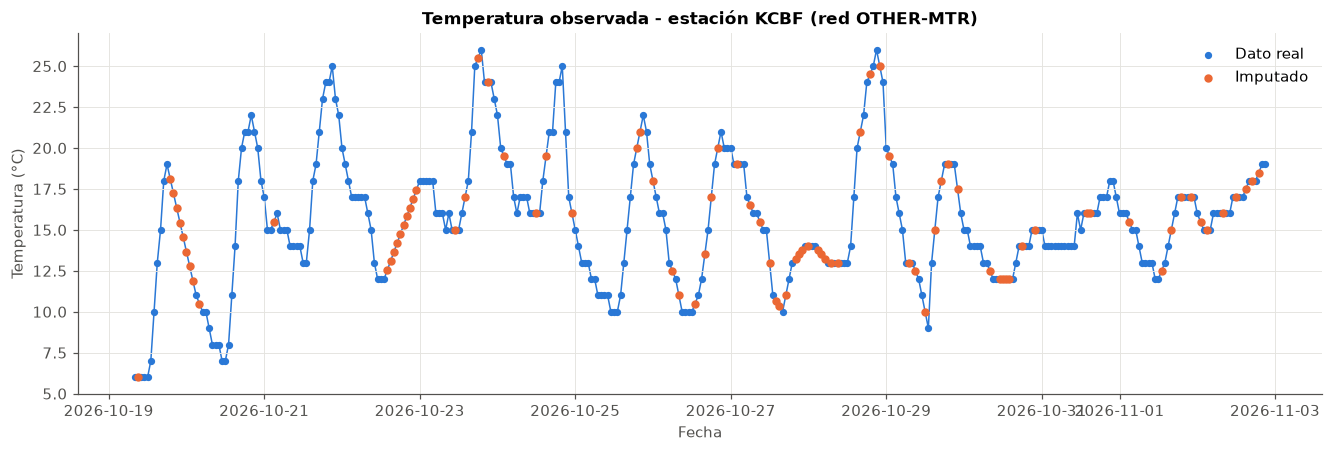

In [14]:
estacion_ejemplo = cobertura.loc[cohorte].query('hueco_max_h >= 9 and hueco_max_h <= 11').sample(1, random_state=0).index[0]
d = panel[panel['station_id'] == estacion_ejemplo]

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(d['target_hour_utc'], d['obs_temp_c'], color=AZUL, lw=1, zorder=1)
ax.scatter(d.loc[~d['obs_temp_c_imputado'], 'target_hour_utc'], d.loc[~d['obs_temp_c_imputado'], 'obs_temp_c'],
           s=14, color=AZUL, label='Dato real', zorder=2)
ax.scatter(d.loc[d['obs_temp_c_imputado'], 'target_hour_utc'], d.loc[d['obs_temp_c_imputado'], 'obs_temp_c'],
           s=20, color=NARANJA, label='Imputado', zorder=3)
ax.set(title=f'Temperatura observada - estación {estacion_ejemplo} (red {cobertura.loc[estacion_ejemplo, "red"]})',
       xlabel='Fecha', ylabel='Temperatura (°C)')
ax.legend(frameon=False)
plt.show()

### 8. Dirección del viento en sectores y hora en forma cíclica

Sólo se codifica la **hora** de forma cíclica (seno/coseno): con 15 días de datos no hay ciclos completos de semana
(168 h ≈ 2 repeticiones) ni de mes, así que un encoding de día-de-semana o mes no aportaría nada confiable -por eso quedan
afuera, a diferencia de un dataset con varios meses u años.

In [15]:
SECTORES = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']

dir_valida = panel['obs_wind_direction_d'].notna()
panel['sector_viento'] = pd.NA
panel.loc[dir_valida, 'sector_viento'] = np.array(SECTORES)[
    (((panel.loc[dir_valida, 'obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)]
panel['sector_viento'] = pd.Categorical(panel['sector_viento'], SECTORES)

panel['hora_local'] = np.nan
for tz, idx in panel.groupby('timeZone').groups.items():
    panel.loc[idx, 'hora_local'] = panel.loc[idx, 'target_hour_utc'].dt.tz_convert(tz).dt.hour
panel['hora_local'] = panel['hora_local'].astype(int)

panel['hora_sin'] = np.sin(2 * np.pi * panel['hora_local'] / 24)
panel['hora_cos'] = np.cos(2 * np.pi * panel['hora_local'] / 24)

panel[['hora_local', 'hora_sin', 'hora_cos', 'sector_viento']].head()

,hora_local,hora_sin,hora_cos,sector_viento
0,21,-0.707107,0.707107,N
1,22,-0.500000,0.866025,N
2,23,-0.258819,0.965926,N
3,0,0.000000,1.000000,N
4,1,0.258819,0.965926,N


### 9. Guardar el panel limpio

In [16]:
panel.to_csv(PROCESSED + 'panel_temporal_limpio.csv', index=False)
print(f'{PROCESSED}panel_temporal_limpio.csv: {panel.shape[0]:,} filas, {panel.shape[1]} columnas, '
      f'{panel["station_id"].nunique()} estaciones')

../data/processed/panel_temporal_limpio.csv: 165,896 filas, 23 columnas, 466 estaciones


# Error de pronóstico: cálculo y análisis temporal

`obs_temp_c` ya pasó por regularización, corrección de saltos imposibles e imputación acotada (sección anterior).
El pronóstico (`fcst_temp_c`) ya captura buena parte del ciclo diurno y estacional de la temperatura, así que el
error resultante -`fcst_temp_c - obs_temp_c`, lo que un modelo de corrección tiene que predecir- puede tener una
dinámica temporal distinta a la de la temperatura cruda: las conclusiones de la sección anterior no se trasladan
automáticamente. Esta sección repite el mismo tipo de diagnóstico (cohorte por intermitencia, imputación acotada,
ADF/KPSS, ACF/PACF) pero sobre `error_temp_c`, y cierra con el feature engineering de esa variable -el que
realmente usan `6_baselines_globales.ipynb` y `8_interpretabilidad.ipynb`.

## 1. Cálculo del error

Se trae `fcst_temp_c` de `mediciones_limpias.csv` (el único pronóstico que hace falta para esta variable) y se
calcula `error_temp_c = fcst_temp_c - obs_temp_c` contra el `obs_temp_c` ya regularizado e imputado del panel -no
contra el original de `mediciones_limpias.csv`-, para no heredar saltos horarios imposibles ni huecos sin imputar
que la sección anterior ya corrigió.

In [17]:
import warnings
from statsmodels.tsa.stattools import acf as acf_statsmodels, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fcst = pd.read_csv(PROCESSED + 'mediciones_limpias.csv',
                    usecols=['station_id', 'target_hour_utc', 'fcst_temp_c', 'horizonte_horas'])
fcst['target_hour_utc'] = pd.to_datetime(fcst['target_hour_utc'], utc=True)

assert fcst['horizonte_horas'].nunique() == 1, 'hay más de un horizonte de pronóstico: la unión por estación+hora sería ambigua'
HORIZONTE = int(fcst['horizonte_horas'].iloc[0])
assert not fcst.duplicated(['station_id', 'target_hour_utc']).any(), 'mediciones_limpias tiene pares estación+hora repetidos'

panel = panel.merge(fcst[['station_id', 'target_hour_utc', 'fcst_temp_c']],
                     on=['station_id', 'target_hour_utc'], how='left')
panel['error_temp_c'] = panel['fcst_temp_c'] - panel['obs_temp_c']
panel = panel.drop(columns='fcst_temp_c')

print(f'horizonte = {HORIZONTE}h')
print(f'{100 * panel["error_temp_c"].notna().mean():.1f}% de las filas con error resuelto')


horizonte = 6h
73.9% de las filas con error resuelto


## 2. Cobertura e intermitencia del error, por estación

Mismo criterio que la sección de limpieza (`UMBRAL_HUECO = 12h` separa la intermitencia normal del apagón
compartido), pero medido sobre `error_temp_c`: una estación puede tener la temperatura bien cubierta y el error
(que depende también de la disponibilidad del pronóstico) más gappy, o viceversa.

In [18]:
cobertura_error = panel.dropna(subset=['error_temp_c']).groupby('station_id').apply(resumen_cobertura)
cobertura_error = cobertura_error.join(atributos_estacion)
cobertura_error['hueco_max_h'].describe()


count    466.000000
mean      44.487124
std       52.037092
min        5.000000
25%       11.000000
50%       11.000000
75%      120.000000
max      304.000000
Name: hueco_max_h, dtype: float64

## 3. El apagón compartido, aplicado al error

Igual que en la sección anterior: si el único hueco largo de una estación en `error_temp_c` es la ventana del
apagón (22/10-27/10), no se la descarta por eso -se mide el hueco máximo excluyendo esa ventana, que queda sin
completar.

In [19]:
cobertura_error['hueco_max_h_sin_corte'] = panel.dropna(subset=['error_temp_c']).groupby('station_id').apply(hueco_max_sin_corte)

recuperadas_error = cobertura_error[(cobertura_error['hueco_max_h'] > UMBRAL_HUECO) &
                                     (cobertura_error['hueco_max_h_sin_corte'] <= UMBRAL_HUECO)]
print(f'{len(recuperadas_error)} estaciones cuyo único hueco largo en error_temp_c era el corte compartido -se reincorporan')
print()
siguen_fuera_error = cobertura_error[cobertura_error['hueco_max_h_sin_corte'] > UMBRAL_HUECO]
print(f'{len(siguen_fuera_error)} estaciones con intermitencia propia en error_temp_c -quedan fuera del cohorte del error')


142 estaciones cuyo único hueco largo en error_temp_c era el corte compartido -se reincorporan

2 estaciones con intermitencia propia en error_temp_c -quedan fuera del cohorte del error


## 4. Cohorte de estaciones sobre `error_temp_c`

El universo ya está acotado a las 466 estaciones del cohorte de `obs_temp_c` (sección anterior) -acá se aplica,
dentro de ese universo, el mismo criterio de intermitencia pero sobre el error.

In [20]:
cohorte_error = cobertura_error[cobertura_error['hueco_max_h_sin_corte'] <= UMBRAL_HUECO].index

print(f'Estaciones en el cohorte del error: {len(cohorte_error)} de {len(cohorte)} ({len(cohorte_error) / len(cohorte):.1%})')
print(f'Cobertura media: {cobertura_error.loc[cohorte_error, "cobertura_pct"].mean():.1f}%')


Estaciones en el cohorte del error: 464 de 466 (99.6%)
Cobertura media: 73.9%


## 5. Regularización + imputación acotada del error

`panel` ya viene con una fila por estación y hora (sección anterior), así que no hace falta reindexar: sólo se
filtra al cohorte del error y se interpola linealmente -no `ffill`, por la misma razón que antes- sólo los huecos
cortos (≤12h). El apagón largo queda sin completar, marcado por el flag `error_temp_c_imputado`.

Se trabaja sobre una copia (`panel_error`) para no mezclar esta interpolación -pensada para poder correr
ADF/KPSS/ACF sobre una serie sin huecos- con el `error_temp_c` "crudo" que ya quedó guardado en `panel` (y que es
el que se exporta en `panel_features.csv` y se usa como target en `5_separacion_train_test.ipynb`).

In [21]:
panel_error = panel.loc[panel['station_id'].isin(cohorte_error),
                         ['station_id', 'target_hour_utc', 'error_temp_c', 'obs_wind_direction_d',
                          'obs_rh_pct', 'obs_dewpoint_c', 'obs_windspeed_kmh']].copy()
panel_error = panel_error.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)
assert len(panel_error) == len(cohorte_error) * len(RANGO_COMPLETO), 'panel_error debería venir regularizado'

panel_error['error_temp_c_imputado'] = panel_error['error_temp_c'].isna()
panel_error['error_temp_c'] = panel_error.groupby('station_id')['error_temp_c'].transform(
    lambda s: s.interpolate(method='linear', limit=UMBRAL_HUECO, limit_area='inside'))
panel_error['error_temp_c_imputado'] &= panel_error['error_temp_c'].notna()

print(f'{100 * panel_error["error_temp_c"].isna().mean():.1f}% sigue faltante tras imputar huecos cortos (apagón + bordes de estación)')
print(f'{100 * panel_error["error_temp_c_imputado"].mean():.1f}% de las filas son un hueco corto imputado')


10.4% sigue faltante tras imputar huecos cortos (apagón + bordes de estación)
15.7% de las filas son un hueco corto imputado


### Estaciones sin ningún faltante remanente

ADF y KPSS necesitan una serie completa, sin `NaN`. Las estaciones con el apagón sin completar quedan fuera de
los tests, pero siguen contempladas en el cohorte del error.

In [22]:
pct_faltante_error = panel_error.groupby('station_id')['error_temp_c'].apply(lambda s: s.isna().mean() * 100)
candidatas_error = pct_faltante_error[pct_faltante_error == 0].to_frame('pct_faltante').join(atributos_estacion)

print(f'{len(candidatas_error)} de {len(cohorte_error)} estaciones del cohorte del error sin ningún faltante remanente')

ESTACIONES_EJEMPLO = candidatas_error.sort_values('pct_faltante').drop_duplicates('estado').head(3).index.tolist()
candidatas_error.loc[ESTACIONES_EJEMPLO]


125 de 464 estaciones del cohorte del error sin ningún faltante remanente

,pct_faltante,estado,timeZone,latitud,longitud,elevation,red,categoria
station_id,,,,,,,,
KABI,0.0,TX,America/Chicago,32.41028,-99.68167,544.9824,ASOS-HFM,ok
KABR,0.0,SD,America/Chicago,45.44333,-98.41306,395.9352,ASOS-HFM,ok
KAEX,0.0,LA,America/Chicago,31.33472,-92.55861,27.1272,ASOS-HFM,ok


## 6. ACF ingenuo vs. pares reales: ¿infla la imputación la autocorrelación del error?

Se compara el ACF calculado sobre `panel_error` ya imputado (el único que puede alimentar a ADF/KPSS) contra un
ACF que sólo usa pares de valores reales en cada lag -mismo chequeo que la sección de limpieza hizo con
`obs_temp_c`.

In [23]:
NLAGS = 48


def acf_pares_completos(valores, es_imputado, nlags):
    """Autocorrelación usando, en cada lag, sólo los pares donde las DOS observaciones son reales (no imputadas)."""
    real = pd.Series(valores).where(~pd.Series(es_imputado).to_numpy())
    salida = []
    for k in range(nlags + 1):
        x, y = real, real.shift(k)
        validos = x.notna() & y.notna()
        salida.append(x[validos].corr(y[validos]) if validos.sum() > 2 else np.nan)
    return np.array(salida)


comparacion_error = []
for sid in ESTACIONES_EJEMPLO:
    d = panel_error[panel_error['station_id'] == sid].sort_values('target_hour_utc')
    ingenuo = acf_statsmodels(d['error_temp_c'], nlags=NLAGS, fft=True)
    reales = acf_pares_completos(d['error_temp_c'].values, d['error_temp_c_imputado'].values, NLAGS)
    comparacion_error.append(pd.DataFrame({'station_id': sid, 'lag': range(NLAGS + 1),
                                            'ACF ingenuo': ingenuo, 'ACF pares reales': reales}))

tabla_comparacion_error = pd.concat(comparacion_error).set_index(['station_id', 'lag']).sort_index()
tabla_comparacion_error['diferencia_abs'] = (
    tabla_comparacion_error['ACF ingenuo'] - tabla_comparacion_error['ACF pares reales']).abs()

print('Diferencia absoluta ACF ingenuo vs. pares reales, por estación (lags 1-24):')
print(tabla_comparacion_error.loc[(slice(None), slice(1, 24)), 'diferencia_abs']
      .groupby('station_id').agg(['mean', 'max']).round(3))


Diferencia absoluta ACF ingenuo vs. pares reales, por estación (lags 1-24):
             mean    max
station_id              
KABI        0.027  0.098
KABR        0.028  0.053
KAEX        0.048  0.142


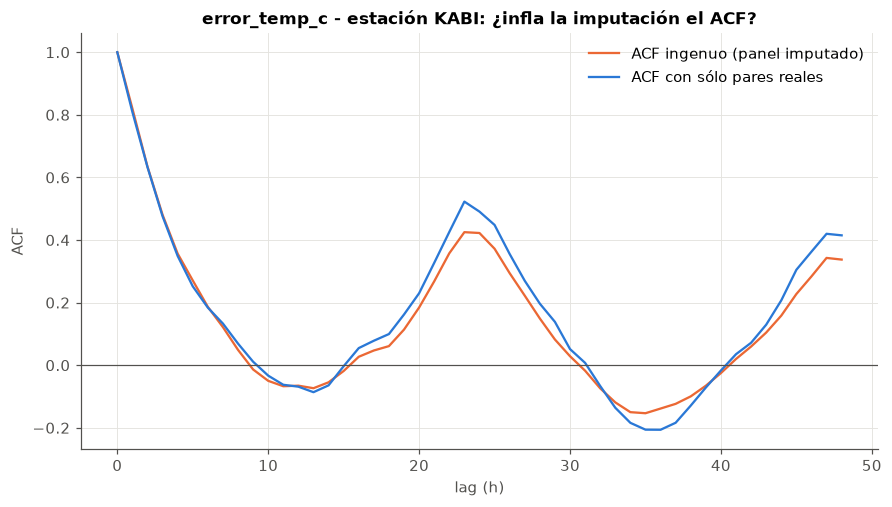

In [24]:
sid_ejemplo = ESTACIONES_EJEMPLO[0]
sub = tabla_comparacion_error.loc[sid_ejemplo].reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(sub['lag'], sub['ACF ingenuo'], color=NARANJA, lw=1.5, label='ACF ingenuo (panel imputado)')
ax.plot(sub['lag'], sub['ACF pares reales'], color=AZUL, lw=1.5, label='ACF con sólo pares reales')
ax.set(title=f'error_temp_c - estación {sid_ejemplo}: ¿infla la imputación el ACF?', xlabel='lag (h)', ylabel='ACF')
ax.legend(frameon=False)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
figuras['14_acf_error_ingenuo_vs_reales'] = fig
plt.show()


La diferencia entre ambos ACF es chica en los lags que importan (1-24h) -la imputación de huecos cortos no está
fabricando la autocorrelación que se reporta más abajo.

## 7. Tests de estacionariedad: ADF/KPSS, cruda vs. diferenciada

Corrido sobre las estaciones sin ningún faltante remanente (sección anterior) -el resto todavía tiene el bloque
del apagón sin completar y rompería el test.

In [25]:
def test_estacionariedad(serie):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        adf_p = adfuller(serie, autolag='AIC')[1]
        kpss_p = kpss(serie, regression='c', nlags='auto')[1]
    return pd.Series({'ADF p-valor': adf_p, 'KPSS p-valor': kpss_p})


filas_estacionariedad_error = []
for sid in candidatas_error.index:
    serie = panel_error[panel_error['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
    if serie.isna().any():
        continue
    for nombre, s in [('cruda', serie), ('diff(1)', serie.diff().dropna())]:
        r = test_estacionariedad(s)
        r['station_id'], r['transformación'] = sid, nombre
        filas_estacionariedad_error.append(r)

tabla_estacionariedad_error = pd.DataFrame(filas_estacionariedad_error).set_index(['station_id', 'transformación'])
print(f'{tabla_estacionariedad_error.index.get_level_values("station_id").nunique()} estaciones aportaron resultado')

resumen_estacionariedad_error = pd.DataFrame({
    'ADF rechaza raíz unitaria (p<0,05)': (tabla_estacionariedad_error['ADF p-valor'] < 0.05).groupby(level='transformación').mean().mul(100),
    'KPSS rechaza estacionariedad (p<0,05)': (tabla_estacionariedad_error['KPSS p-valor'] < 0.05).groupby(level='transformación').mean().mul(100),
}).round(1)
resumen_estacionariedad_error


125 estaciones aportaron resultado


,"ADF rechaza raíz unitaria (p<0,05)","KPSS rechaza estacionariedad (p<0,05)"
transformación,,
cruda,99.2,31.2
diff(1),100.0,0.0


Mismo patrón que `obs_temp_c`: ADF ya "pasa" en la serie cruda en casi todas las estaciones, pero KPSS disiente en
una porción no menor -señal de que queda estructura de nivel o ciclo. Diferenciando en lag 1, ambos tests
coinciden en estacionariedad en prácticamente el 100% de los casos.

## 8. ACF/PACF: ¿sobrevive el ciclo diario del error a la diferenciación?

Que la serie diferenciada sea estacionaria para ADF/KPSS no prueba ausencia de estructura periódica -esos tests
prueban raíz unitaria y estacionariedad de nivel, no autocorrelación en un lag puntual como 24h.

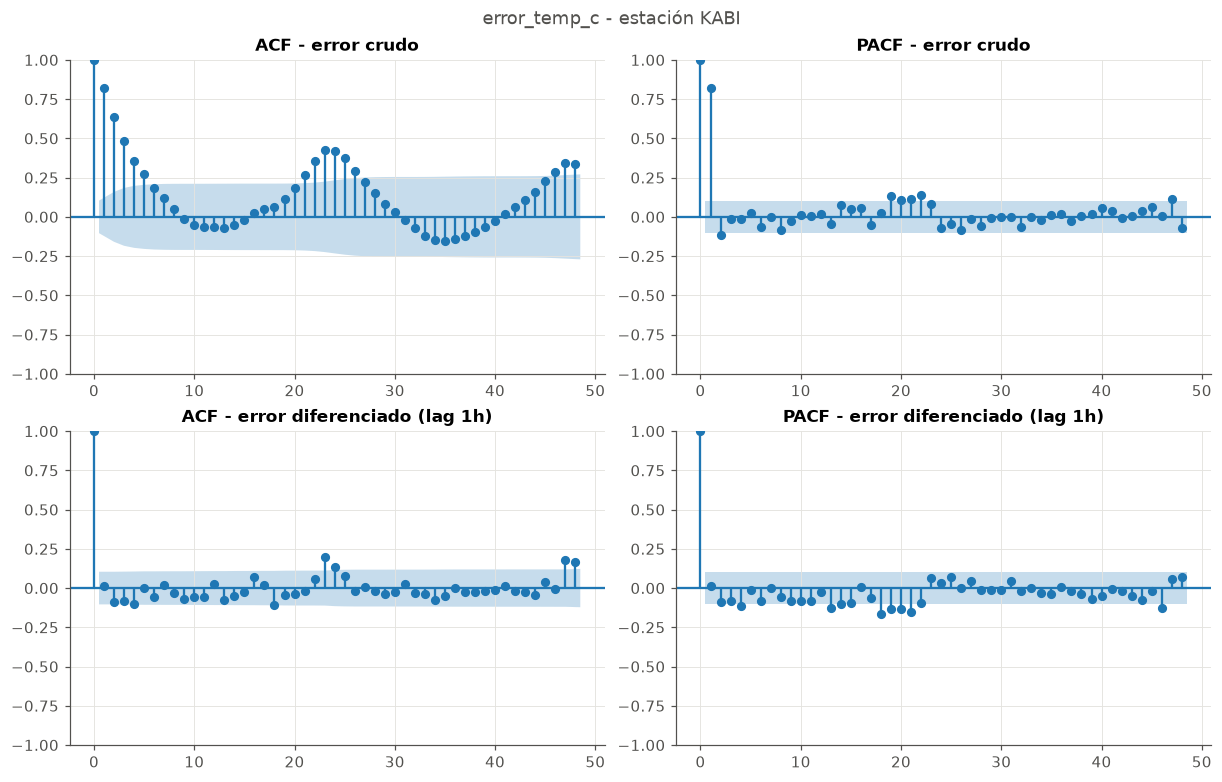

In [26]:
serie = panel_error[panel_error['station_id'] == sid_ejemplo].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
serie_diff = serie.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
plot_acf(serie, lags=48, ax=axes[0, 0], title='ACF - error crudo')
plot_pacf(serie, lags=48, ax=axes[0, 1], method='ywm', title='PACF - error crudo')
plot_acf(serie_diff, lags=48, ax=axes[1, 0], title='ACF - error diferenciado (lag 1h)')
plot_pacf(serie_diff, lags=48, ax=axes[1, 1], method='ywm', title='PACF - error diferenciado (lag 1h)')
fig.suptitle(f'error_temp_c - estación {sid_ejemplo}', color=GRIS_TEXTO)
figuras['15_acf_pacf_error_crudo_vs_diff'] = fig
plt.show()


In [27]:
LAGS_H = [1, 2, 3, 6, 12, 18, 24, 48]

filas_acf_cohorte_error = []
for sid in candidatas_error.index:
    tramo = panel_error[panel_error['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
    if tramo.isna().any():
        continue
    n = len(tramo)
    umbral_sig = 1.96 / np.sqrt(n)
    acf_cruda = acf_statsmodels(tramo, nlags=max(LAGS_H), fft=True)
    tramo_diff = tramo.diff().dropna()
    acf_diff = acf_statsmodels(tramo_diff, nlags=max(LAGS_H), fft=True)
    fila = {'station_id': sid, 'n': n}
    for lag in LAGS_H:
        fila[f'cruda_h{lag}'] = acf_cruda[lag]
        fila[f'diff_h{lag}'] = acf_diff[lag]
        fila[f'diff_h{lag}_sig'] = abs(acf_diff[lag]) > umbral_sig
    filas_acf_cohorte_error.append(fila)

tabla_acf_cohorte_error = pd.DataFrame(filas_acf_cohorte_error)

resumen_acf_error = pd.DataFrame({
    'ACF cruda (prom.)': [tabla_acf_cohorte_error[f'cruda_h{l}'].mean() for l in LAGS_H],
    'ACF diferenciada (prom.)': [tabla_acf_cohorte_error[f'diff_h{l}'].mean() for l in LAGS_H],
    '% diferenciada significativo': [tabla_acf_cohorte_error[f'diff_h{l}_sig'].mean() * 100 for l in LAGS_H],
}, index=[f'{l} h' for l in LAGS_H]).round(3)
resumen_acf_error


,ACF cruda (prom.),ACF diferenciada (prom.),% diferenciada significativo
1 h,0.814,-0.020,16.0
2 h,0.639,-0.027,10.4
3 h,0.476,-0.048,15.2
6 h,0.107,-0.037,12.8
12 h,-0.096,0.055,27.2
18 h,0.012,-0.012,8.8
24 h,0.364,0.215,87.2
48 h,0.268,0.165,65.6


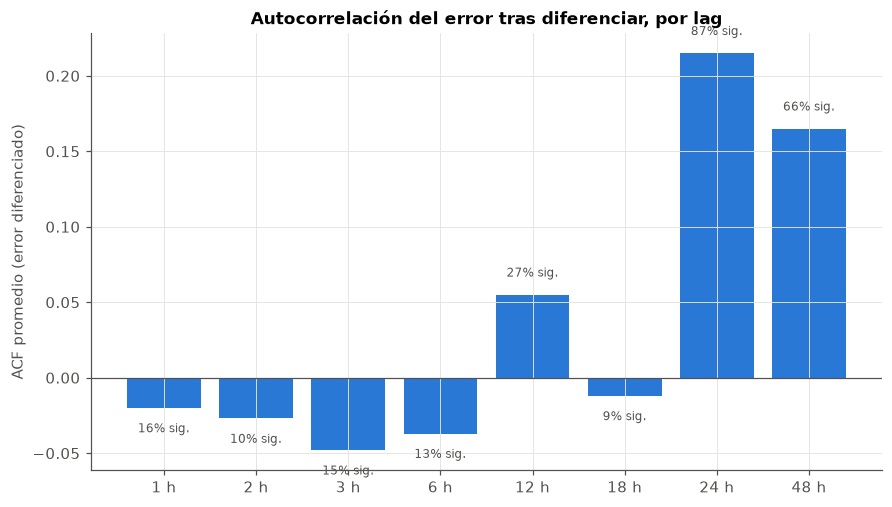

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.bar([f'{l} h' for l in LAGS_H], resumen_acf_error['ACF diferenciada (prom.)'], color=AZUL)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
ax.set(ylabel='ACF promedio (error diferenciado)', title='Autocorrelación del error tras diferenciar, por lag')
for i, (v, pct) in enumerate(zip(resumen_acf_error['ACF diferenciada (prom.)'], resumen_acf_error['% diferenciada significativo'])):
    ax.text(i, v + (0.01 if v >= 0 else -0.01), f'{pct:.0f}% sig.', ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=8, color=GRIS_TEXTO)
figuras['16_acf_error_diferenciada_por_lag'] = fig
plt.show()


### PACF sobre el cohorte: ¿`lag24` y `lag48` aportan información independiente?

La ACF de la sección anterior dice que hay autocorrelación significativa en lag 24h y en lag 48h, pero no dice si
son dos señales independientes o si lag 48h sólo repite, de rebote, lo que ya aporta lag 24h (el doble del período).
Para eso sirve la PACF: en cada lag, mide la correlación con la serie controlando por todos los lags más cortos -si
la PACF en lag 48h deja de ser significativa una vez que lag 24h (y todos los lags intermedios) ya están
"explicados", lag 48h no aporta nada nuevo al modelo y se puede dropear del feature set sin perder información.

Mismo cohorte, mismo umbral de significancia (±1,96/√n) y misma serie diferenciada (lag 1) que la sección anterior
-para no mezclar el efecto que ya tiene diferenciar con el de controlar por lags cortos-, y `method='ywm'` (el mismo
que ya se usó para el PACF de la estación de ejemplo, más estable que OLS en lags altos).

In [29]:
from statsmodels.tsa.stattools import pacf as pacf_statsmodels

LAGS_PACF = [6, 12, 18, 24, 48]

filas_pacf_cohorte_error = []
for sid in candidatas_error.index:
    tramo = panel_error[panel_error['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
    if tramo.isna().any():
        continue
    tramo_diff = tramo.diff().dropna()
    n = len(tramo_diff)
    umbral_sig = 1.96 / np.sqrt(n)
    pacf_vals = pacf_statsmodels(tramo_diff, nlags=max(LAGS_PACF), method='ywm')
    fila = {'station_id': sid}
    for lag in LAGS_PACF:
        fila[f'pacf_h{lag}'] = pacf_vals[lag]
        fila[f'pacf_h{lag}_sig'] = abs(pacf_vals[lag]) > umbral_sig
    filas_pacf_cohorte_error.append(fila)

tabla_pacf_cohorte_error = pd.DataFrame(filas_pacf_cohorte_error)

resumen_pacf_error = pd.DataFrame({
    'PACF diferenciada (prom.)': [tabla_pacf_cohorte_error[f'pacf_h{l}'].mean() for l in LAGS_PACF],
    '% significativo': [tabla_pacf_cohorte_error[f'pacf_h{l}_sig'].mean() * 100 for l in LAGS_PACF],
}, index=[f'{l} h' for l in LAGS_PACF]).round(3)
resumen_pacf_error


,PACF diferenciada (prom.),% significativo
6 h,-0.051,16.8
12 h,0.008,12.8
18 h,-0.092,44.0
24 h,0.114,52.0
48 h,0.057,19.2


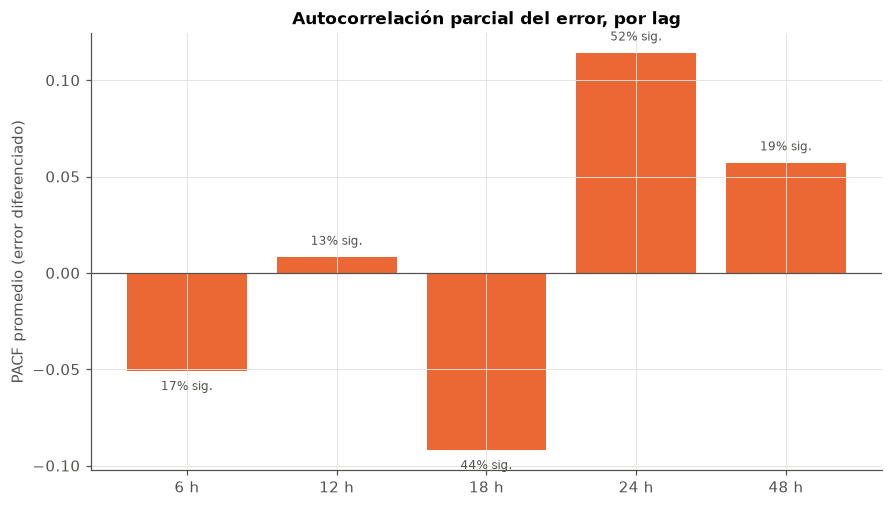

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.bar([f'{l} h' for l in LAGS_PACF], resumen_pacf_error['PACF diferenciada (prom.)'], color=NARANJA)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
ax.set(ylabel='PACF promedio (error diferenciado)', title='Autocorrelación parcial del error, por lag')
for i, (v, pct) in enumerate(zip(resumen_pacf_error['PACF diferenciada (prom.)'], resumen_pacf_error['% significativo'])):
    ax.text(i, v + (0.005 if v >= 0 else -0.005), f'{pct:.0f}% sig.', ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=8, color=GRIS_TEXTO)
figuras['17_pacf_error_por_lag'] = fig
plt.show()


La PACF confirma la sospecha que motivó este chequeo: `lag24` sigue aportando información independiente al
controlar por los lags más cortos (**52,0%** de las estaciones con PACF significativa), pero `lag48` cae a
**19,2%** -apenas por encima de `lag6` (16,8%) y muy por debajo de lo que sugería la ACF simple de la sección
anterior (65,6%). Buena parte de la autocorrelación "propia" que mostraba `lag48` en la ACF es, controlando por
`lag24`, redundante: es el eco del ciclo diario que ya captura `lag24`, no una señal independiente en el doble de
período.

**Decisión**: se dropea `lag48` del feature set final de la sección de feature engineering -`lag6` y `lag24`
alcanzan; agregar `lag48` sumaría una columna con más faltante (los lags largos pierden más filas al principio de
cada estación) sin aportar señal independiente en la mayoría de las estaciones.

## 9. Correlación cruzada (CCF): ¿qué lag de humedad, punto de rocío y viento predice el error?

Hallazgo 6 de `revision-pipeline-error.md`: si se quiere sumar una variable de sensor nueva como feature del
error (más allá de la dirección del viento, ya incluida), el criterio correcto para elegir su lag es la
correlación cruzada (CCF) contra `error_temp_c` -no el ACF univariado de la variable consigo misma, que es el
estadístico equivocado para esta pregunta (eso fue justamente lo que se sacó de acá en el hallazgo 3).

Candidatas: `obs_rh_pct`, `obs_dewpoint_c`, `obs_windspeed_kmh` (humedad relativa, punto de rocío y velocidad del
viento -ya regularizadas e imputadas en `panel`, sección "Limpieza de datos"). `obs_temp_c` no aplica como
predictor nuevo: `error_temp_c` ya se calcula directamente a partir de ella.

Se mide, para cada variable y cada lag `h` (múltiplos de 6h, igual que el resto de esta sección -por el horizonte
del pronóstico, `lag1` no es una opción disponible al momento de corregir), la correlación de Pearson entre
`obs_<var>(t-h)` y `error_temp_c(t)`. A diferencia de ADF/KPSS, la correlación tolera pares con `NaN` (se
descartan por pares, no exige una estación con cero faltantes), así que se calcula sobre las 464 estaciones del
cohorte del error completo, no sólo sobre las 125 con serie íntegra.

In [31]:
LAGS_CCF = [6, 12, 18, 24, 48]
VARIABLES_CCF = ['obs_rh_pct', 'obs_dewpoint_c', 'obs_windspeed_kmh']

panel_ccf = panel_error[['station_id', 'target_hour_utc', 'error_temp_c']].merge(
    panel[['station_id', 'target_hour_utc'] + VARIABLES_CCF],
    on=['station_id', 'target_hour_utc'], how='left')


def ccf_lag(serie_obs, serie_error, lag):
    """Correlación de Pearson entre la variable observada rezagada `lag` horas y error_temp_c en t,
    sobre los pares con ambos valores no nulos."""
    x = serie_obs.shift(lag)
    validos = x.notna() & serie_error.notna()
    n = int(validos.sum())
    r = x[validos].corr(serie_error[validos]) if n > 2 else np.nan
    return r, n


filas_ccf = []
for sid, g in panel_ccf.groupby('station_id'):
    g = g.sort_values('target_hour_utc')
    for var in VARIABLES_CCF:
        for lag in LAGS_CCF:
            r, n = ccf_lag(g[var], g['error_temp_c'], lag)
            if np.isnan(r):
                continue
            umbral_sig = 1.96 / np.sqrt(n)
            filas_ccf.append({'station_id': sid, 'variable': var, 'lag': lag, 'ccf': r, 'n': n,
                               'significativo': abs(r) > umbral_sig})

tabla_ccf = pd.DataFrame(filas_ccf)

resumen_ccf = (tabla_ccf.groupby(['variable', 'lag'])
               .agg(ccf_promedio=('ccf', 'mean'), pct_significativo=('significativo', lambda s: 100 * s.mean()),
                    n_estaciones=('station_id', 'nunique'))
               .round(3))
resumen_ccf


C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


ccf_promedio  pct_significativo  n_estaciones
variable          lag                                               
obs_dewpoint_c    6           0.034             53.664           464
                  12         -0.001             51.293           464
                  18          0.003             52.586           464
                  24          0.009             55.603           464
                  48         -0.026             51.293           464
obs_rh_pct        6          -0.161             71.983           464
                  12          0.030             53.233           464
                  18          0.182             70.690           464
                  24         -0.048             53.017           464
                  48         -0.120             66.379           464
obs_windspeed_kmh 6           0.074             50.763           459
                  12         -0.008             42.484           459
                  18         -0.109             59.041           459
                  24         -0.025             51.852           459
                  48          0.013             42.358           458

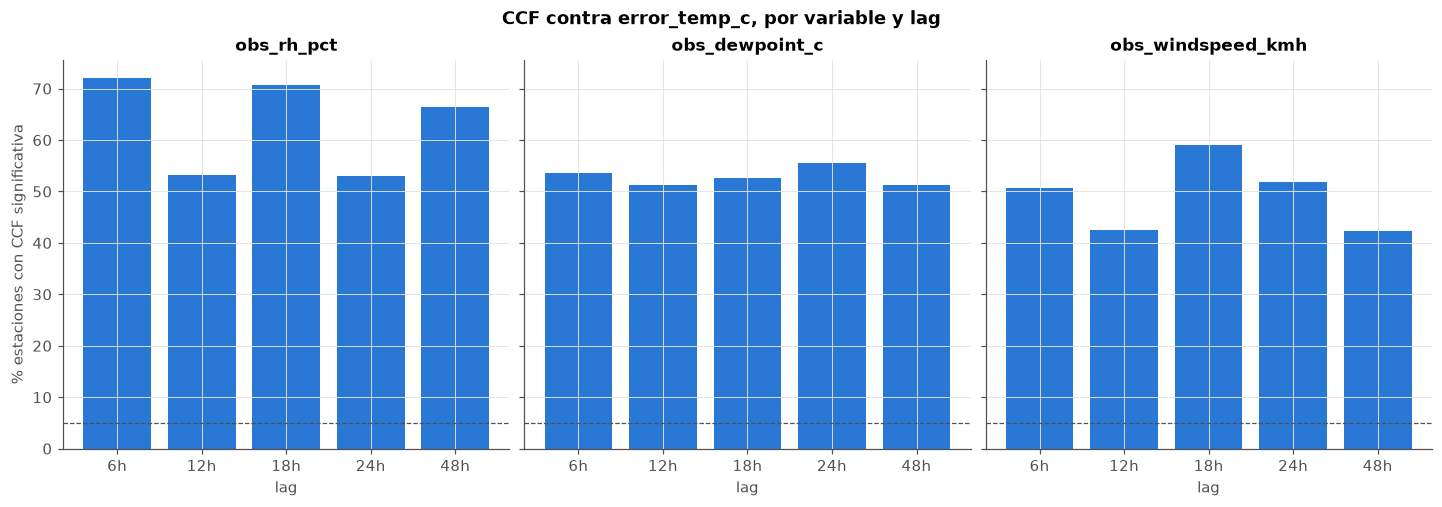

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), constrained_layout=True, sharey=True)
for ax, var in zip(axes, VARIABLES_CCF):
    sub = resumen_ccf.loc[var]
    ax.bar([f'{l}h' for l in sub.index], sub['pct_significativo'], color=AZUL)
    ax.axhline(5, color=GRIS_TEXTO, lw=0.8, ls='--')  # % esperable por azar a nivel 95%
    ax.set(title=var, xlabel='lag', ylabel='% estaciones con CCF significativa' if var == VARIABLES_CCF[0] else '')
fig.suptitle('CCF contra error_temp_c, por variable y lag', fontweight='bold')
figuras['18_ccf_obs_vs_error'] = fig
plt.show()


### ¿Es un artefacto del ciclo diario compartido? CCF sobre las series diferenciadas

`error_temp_c` y las 3 variables candidatas tienen todas su propio ciclo diario (la primera, por construcción,
hereda el de `obs_temp_c`; humedad y punto de rocío también varían con la hora del día). Dos series cíclicas
pueden mostrar CCF alta en varios lags sólo por compartir esa periodicidad, sin que haya una relación real entre
ellas -el mismo riesgo que motivó comparar "cruda vs. diferenciada" en las secciones 7-8. Se repite el cálculo
sobre las series diferenciadas en lag 1 (`diff()` de la variable candidata rezagada, contra `diff()` de
`error_temp_c`), que saca la mayor parte del ciclo diario de ambas series.

In [33]:
filas_ccf_diff = []
for sid, g in panel_ccf.groupby('station_id'):
    g = g.sort_values('target_hour_utc')
    error_diff = g['error_temp_c'].diff()
    for var in VARIABLES_CCF:
        var_diff = g[var].diff()
        for lag in LAGS_CCF:
            r, n = ccf_lag(var_diff, error_diff, lag)
            if np.isnan(r):
                continue
            umbral_sig = 1.96 / np.sqrt(n)
            filas_ccf_diff.append({'station_id': sid, 'variable': var, 'lag': lag, 'ccf': r, 'n': n,
                                    'significativo': abs(r) > umbral_sig})

tabla_ccf_diff = pd.DataFrame(filas_ccf_diff)

resumen_ccf_diff = (tabla_ccf_diff.groupby(['variable', 'lag'])
                    .agg(ccf_promedio=('ccf', 'mean'), pct_significativo=('significativo', lambda s: 100 * s.mean()),
                         n_estaciones=('station_id', 'nunique'))
                    .round(3))
resumen_ccf_diff


C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


ccf_promedio  pct_significativo  n_estaciones
variable          lag                                               
obs_dewpoint_c    6           0.030              8.190           464
                  12         -0.045             16.164           464
                  18          0.013              9.483           464
                  24         -0.036             21.552           464
                  48         -0.017             16.595           464
obs_rh_pct        6          -0.105             49.353           464
                  12          0.019             12.500           464
                  18          0.073             28.879           464
                  24          0.008             14.871           464
                  48         -0.030             15.302           464
obs_windspeed_kmh 6           0.030             10.458           459
                  12         -0.006              6.536           459
                  18         -0.027              7.407           459
                  24         -0.032             12.418           459
                  48         -0.010              6.550           458

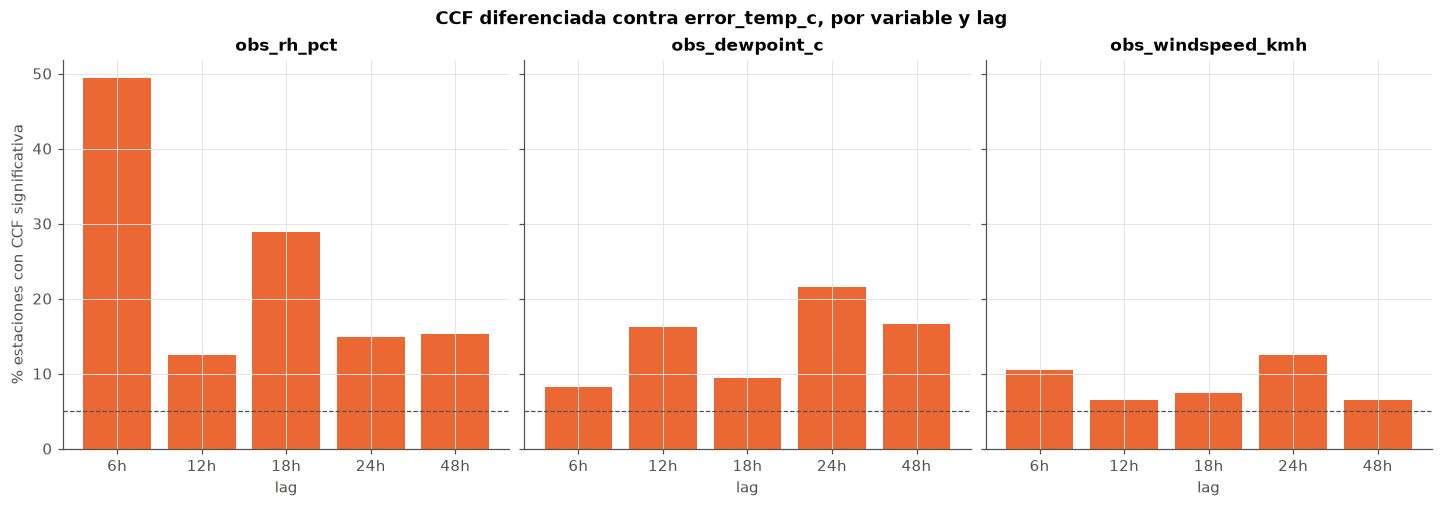

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), constrained_layout=True, sharey=True)
for ax, var in zip(axes, VARIABLES_CCF):
    sub = resumen_ccf_diff.loc[var]
    ax.bar([f'{l}h' for l in sub.index], sub['pct_significativo'], color=NARANJA)
    ax.axhline(5, color=GRIS_TEXTO, lw=0.8, ls='--')
    ax.set(title=var, xlabel='lag', ylabel='% estaciones con CCF significativa' if var == VARIABLES_CCF[0] else '')
fig.suptitle('CCF diferenciada contra error_temp_c, por variable y lag', fontweight='bold')
figuras['19_ccf_diferenciada_obs_vs_error'] = fig
plt.show()


La CCF "cruda" (primer gráfico) muestra 50-72% de estaciones "significativas" en casi todos los lags de las 3
variables -a primera vista, señal fuerte en todos lados. Pero al diferenciar (segundo gráfico, que saca el ciclo
diario compartido entre cada variable y `error_temp_c`) casi todo eso se desinfla a niveles cercanos al 5% que se
esperaría por azar:

- **`obs_dewpoint_c`**: no sobrevive en ningún lag (8-22% tras diferenciar, contra 51-56% en crudo). El punto de
  rocío no tiene relación real con el error más allá de compartir ciclo diario con él -**no es candidata**.
- **`obs_windspeed_kmh`**: tampoco sobrevive (6,5-12,4% tras diferenciar, contra 42-59% en crudo) -**no es
  candidata**.
- **`obs_rh_pct`**: es la única que deja algo real. `lag6` pasa de -0,161 (71,98% "significativo") en crudo a
  **-0,105 (49,4% significativo) ya diferenciado** -se achica pero sigue muy por encima del 5% esperable por azar,
  así que hay señal genuina, no sólo ciclo compartido. `lag18` también tenía un valor llamativo en crudo (+0,182,
  70,7%) que cae a 0,073/28,9% diferenciado -mayormente artefacto, más débil que `lag6` pero no completamente
  ausente. Los demás lags de humedad (12, 24, 48) caen a 13-15%, ruido.

**Conclusión**: de las 3 variables candidatas, sólo `obs_rh_pct_lag6` (humedad relativa, 6h antes del target -el
dato más reciente disponible al momento de corregir) tiene una correlación cruzada real con `error_temp_c`, no
explicada por el ciclo diario compartido. Es candidata razonable para sumar a `7_modelado_global.ipynb` y dejar
que Lasso/feature importance confirmen si aporta sobre lo que ya capturan los lags del propio error. `obs_dewpoint_c`
y `obs_windspeed_kmh` quedan descartadas como predictores nuevos -no hay evidencia de que algún lag de ninguna de
las dos ayude.

## 10. Conclusiones de esta sección

El cohorte del error (sección 4) deja fuera sólo 2 de las 466 estaciones (99,6% pasa): la intermitencia propia
de `error_temp_c`, más allá de la de `obs_temp_c`, es marginal.

`error_temp_c` no es ruido blanco: autocorrelación de corto plazo fuerte que decae rápido, y un ciclo diario real
que sobrevive a la diferenciación en el **87,2%** del cohorte en el lag 24h, y en el **65,6%** en el lag 48h (tabla
de la sección anterior). Esto es lo que explica que `naive_estacional` (lag 24) sea el mejor de los baselines "no
triviales" en `6_baselines_globales.ipynb`, y por qué ninguno le gana a "no corregir": la correlación en 24h es
real pero moderada.

En estacionariedad: ADF rechaza raíz unitaria en el 99,2% de las estaciones ya en la serie cruda, pero KPSS
disiente en el 31,2% de los casos -señal de que queda estructura de nivel o ciclo-; diferenciando en lag 1, ambos
tests coinciden en estacionariedad en el 100% -mismo patrón que `obs_temp_c`.

La sección de feature engineering que sigue usa estos hallazgos para elegir qué lags incluir (6, 24 y 48 -no 12 ni
18, que no mostraron señal significativa) y para anclar todo en `shift(HORIZONTE)` en vez de `shift(1)`, por el
horizonte real de 6h del pronóstico.

# Feature engineering

## Features de las variables observadas

- Rolling features
- Encoding cíclico para variables circulares
- Features espaciales: correlación información de estaciones vecinas (ej: mean(temp_obs LAGGED de k vecinas más cercanas por estación))

Los lags de las variables observadas (`shift(1)`/`shift(24)`) no se incluyen acá: no se usan en ningún modelo de
corrección del error (violan el horizonte de 6h del pronóstico y, de cualquier forma, el ACF univariado de una
observación no es el estadístico correcto para decidir si predice el *error* -haría falta correlación cruzada
contra `error_temp_c`). Quedan reemplazados por los features de `error_temp_c` de la sección siguiente, que sí
alimentan `6_baselines_globales.ipynb` y `8_interpretabilidad.ipynb`.


### 1. Rolling features

Promedio móvil de las últimas 3 horas, para las 4 variables continuas: suaviza el ruido hora a hora sin diluir del todo
la dinámica reciente (en la sección de ACF de `obs_temp_c`, los lags 2-3 todavía mostraban autocorrelación alta antes de
diferenciar).

La ventana se calcula sobre el **shift(1)** de la serie, no sobre la serie misma: si no se corre un paso, la media móvil
de la hora *t* incluiría el propio valor de *t* -la misma lógica de "no usar información que todavía no está disponible"
que se usa en los lags del error, más abajo. Por eso esta media cubre las horas *t-1, t-2, t-3*, no *t, t-1, t-2*.

El flag `_imputado` acá es `True` si **alguna** de las horas que entran en la ventana fue imputada.

In [35]:
VENTANA_ROLLING = 3  # horas

for var in VARIABLES_CONTINUAS:
    panel[f'{var}_roll{VENTANA_ROLLING}_mean'] = panel.groupby('station_id')[var].transform(
        lambda s: s.shift(1).rolling(VENTANA_ROLLING, min_periods=1).mean())
    panel[f'{var}_roll{VENTANA_ROLLING}_mean_imputado'] = panel.groupby('station_id')[f'{var}_imputado'].transform(
        lambda s: s.shift(1).fillna(False).rolling(VENTANA_ROLLING, min_periods=1).max()).astype(bool)

print(f'Rolling mean ({VENTANA_ROLLING} h, sobre shift(1)) agregado para {len(VARIABLES_CONTINUAS)} variables continuas.')

Rolling mean (3 h, sobre shift(1)) agregado para 4 variables continuas.


### 2. Encoding cíclico para la dirección del viento

La hora ya se codificó de forma cíclica en la limpieza (`hora_sin`/`hora_cos`, sección 8). La otra variable circular del
panel es la dirección del viento: `sector_viento` la discretiza en 8 sectores categóricos, pero para un modelo que use
features numéricas conviene además una versión continua seno/coseno -con la misma idea de que 350° y 10° tienen que
quedar cerca en el espacio de features, no en los extremos opuestos de una escala de 0 a 360.

In [36]:
panel['obs_wind_direction_sin'] = np.sin(np.deg2rad(panel['obs_wind_direction_d']))
panel['obs_wind_direction_cos'] = np.cos(np.deg2rad(panel['obs_wind_direction_d']))

panel['obs_wind_direction_sin_lag1'] = panel.groupby('station_id')['obs_wind_direction_sin'].shift(1)
panel['obs_wind_direction_cos_lag1'] = panel.groupby('station_id')['obs_wind_direction_cos'].shift(1)

# Flag de leakage: True si el valor de origen (1h atrás) fue imputado
flag_lag1_viento = panel.groupby('station_id')['obs_wind_direction_d_imputado'].shift(1).fillna(False).astype(bool)
panel['obs_wind_direction_sin_lag1_imputado'] = flag_lag1_viento
panel['obs_wind_direction_cos_lag1_imputado'] = flag_lag1_viento

panel[['obs_wind_direction_d', 'obs_wind_direction_sin', 'obs_wind_direction_cos',
       'obs_wind_direction_sin_lag1', 'obs_wind_direction_cos_lag1']].head()


,obs_wind_direction_d,obs_wind_direction_sin,obs_wind_direction_cos,obs_wind_direction_sin_lag1,obs_wind_direction_cos_lag1
0,0.0,0.0,1.0,NaN,NaN
1,0.0,0.0,1.0,0.0,1.0
2,0.0,0.0,1.0,0.0,1.0
3,0.0,0.0,1.0,0.0,1.0
4,0.0,0.0,1.0,0.0,1.0


### 3. Features espaciales: promedio de las K estaciones vecinas más cercanas

Para cada estación, se buscan las `K` estaciones más cercanas (distancia euclídea sobre latitud/longitud -una
aproximación razonable para rankear vecinas a esta escala continental, no para medir distancia real en km) **dentro del
cohorte**: son las únicas con la serie regularizada e imputada en `panel`, así que son las únicas para las que tiene
sentido construir un lag.

El feature es el promedio, entre esas `K` vecinas, del **lag 1** de cada variable (no el valor crudo de la misma hora):
usar el valor de la hora *t* de una vecina para predecir la hora *t* de la estación en cuestión sería, de nuevo,
información que en la práctica no está más disponible que la propia observación que se quiere explicar.

In [37]:
from scipy.spatial.distance import cdist

K_VECINAS = 2
coords = atributos_estacion.loc[cohorte, ['latitud', 'longitud']]
dist_matrix = pd.DataFrame(cdist(coords, coords), index=coords.index, columns=coords.index)
vecinas = {e: dist_matrix.loc[e].drop(e).nsmallest(K_VECINAS).index.tolist() for e in coords.index}

# Continuas con lag1 calculado al vuelo; la dirección del viento queda afuera: promediar ángulos crudos entre
# vecinas no tiene sentido (es la misma razón por la que se encodeó seno/coseno en la sección anterior)
VARIABLES_ESPACIALES = ['obs_temp_c', 'obs_rh_pct', 'obs_dewpoint_c']

for var in VARIABLES_ESPACIALES:
    lag1 = panel.groupby('station_id')[var].shift(1)
    lag1_imputado = panel.groupby('station_id')[f'{var}_imputado'].shift(1).fillna(False).astype(bool)
    pivot_lag1 = panel.assign(_lag1=lag1).pivot(index='target_hour_utc', columns='station_id', values='_lag1')
    pivot_imputado = panel.assign(_lag1_imp=lag1_imputado).pivot(index='target_hour_utc', columns='station_id', values='_lag1_imp')

    col_mean, col_imp = f'{var}_vecinas_lag1_mean', f'{var}_vecinas_lag1_mean_imputado'
    vecinas_mean = pd.DataFrame({e: pivot_lag1[vecinas[e]].mean(axis=1) for e in coords.index}).rename_axis('target_hour_utc')
    vecinas_imputado = pd.DataFrame({e: pivot_imputado[vecinas[e]].any(axis=1) for e in coords.index}).rename_axis('target_hour_utc')

    panel = panel.merge(
        vecinas_mean.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_mean),
        on=['target_hour_utc', 'station_id'], how='left')
    panel = panel.merge(
        vecinas_imputado.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_imp),
        on=['target_hour_utc', 'station_id'], how='left')

print(f'K={K_VECINAS} vecinas por estación (distancia euclídea lat/long). Features espaciales: {VARIABLES_ESPACIALES}')
panel[[f'{v}_vecinas_lag1_mean' for v in VARIABLES_ESPACIALES]].describe().T[['count', 'mean', 'std']]


K=2 vecinas por estación (distancia euclídea lat/long). Features espaciales: ['obs_temp_c', 'obs_rh_pct', 'obs_dewpoint_c']


,count,mean,std
obs_temp_c_vecinas_lag1_mean,158931.0,14.865698,6.465794
obs_rh_pct_vecinas_lag1_mean,158910.0,74.596314,19.011738
obs_dewpoint_c_vecinas_lag1_mean,158992.0,9.661954,5.337043


### 4. Resumen de features de las variables observadas

Chequeo rápido: cuánto falta y cuánto está "contaminado" por imputación en cada feature nueva. Se espera una tasa de
`_imputado` parecida al ~20 % que ya tenía cada variable de origen.

In [38]:
FEATURES_CON_FLAG = (
    [f'{v}_roll{VENTANA_ROLLING}_mean' for v in VARIABLES_CONTINUAS] +
    ['obs_wind_direction_sin_lag1', 'obs_wind_direction_cos_lag1'] +
    [f'{v}_vecinas_lag1_mean' for v in VARIABLES_ESPACIALES]
)

resumen_features = pd.DataFrame({
    'faltante_pct': panel[FEATURES_CON_FLAG].isna().mean().mul(100).round(1),
    'imputado_pct': pd.Series({f: 100 * panel[f'{f}_imputado'].mean() for f in FEATURES_CON_FLAG}).round(1),
})
resumen_features


,faltante_pct,imputado_pct
obs_temp_c_roll3_mean,10.6,41.4
obs_rh_pct_roll3_mean,10.7,42.3
obs_windspeed_kmh_roll3_mean,10.3,41.1
obs_dewpoint_c_roll3_mean,10.5,40.8
obs_wind_direction_sin_lag1,10.5,20.4
obs_wind_direction_cos_lag1,10.5,20.4
obs_temp_c_vecinas_lag1_mean,4.2,30.6
obs_rh_pct_vecinas_lag1_mean,4.2,31.6
obs_dewpoint_c_vecinas_lag1_mean,4.2,29.8


## Features del error de pronóstico

Mismos módulos que la sección anterior -lags, rolling mean, dirección de viento cíclica, promedio de vecinas-, más
un lag de humedad relativa que surge del hallazgo 6, con tres diferencias que se desprenden directamente del
diagnóstico de arriba:

1. **El ancla de todo lag/rolling/feature espacial pasa de `shift(1)` a `shift(HORIZONTE)` = `shift(6)`.** Un
   feature construido con `shift(1)` es válido para describir la dinámica de la serie, pero no para corregir un
   pronóstico en tiempo real: el punto más reciente que efectivamente está disponible al momento de emitir la
   corrección es `t-6`, no `t-1`.
2. **Los lags de `error_temp_c` que se agregan son `lag6` y `lag24`.** `lag6` es el más reciente disponible (señal
   débil pero no nula); `lag24` captura el ciclo diario y la PACF de la sección anterior confirma que aporta
   información independiente de los lags más cortos (52,0% de las estaciones). No se agrega `lag12` ni `lag18`
   (no superaron el umbral de significancia en la ACF diferenciada) ni `lag48`: aunque su ACF simple era
   significativa en 65,6% de las estaciones, la PACF cae a 19,2% una vez controlado por `lag24` -mayormente
   redundante, no información nueva.
3. **Se agrega `obs_rh_pct_lag{HORIZONTE}`.** La CCF de la sección 9 encontró que es la única variable de sensor
   candidata (de las 3 que se probaron) con correlación real contra `error_temp_c` -no explicada por el ciclo
   diario compartido-, así que se suma con el mismo criterio de horizonte que el resto.

### 1. Lags de `error_temp_c` (6 y 24)

In [39]:
def _flag_lag(df, col_imputado, lag):
    """Flag de leakage para una feature de lag: True si el valor de origen fue imputado."""
    return df.groupby('station_id')[col_imputado].shift(lag).fillna(False).astype(bool)


LAGS_FEATURE = [HORIZONTE, 24]

for lag in LAGS_FEATURE:
    panel_error[f'error_temp_c_lag{lag}'] = panel_error.groupby('station_id')['error_temp_c'].shift(lag)
    panel_error[f'error_temp_c_lag{lag}_imputado'] = _flag_lag(panel_error, 'error_temp_c_imputado', lag)

print(f'Lags agregados: {LAGS_FEATURE}')


Lags agregados: [6, 24]


### 2. Rolling mean, anclado en `shift(HORIZONTE)`

Promedio de las 3 horas resueltas más recientes al momento de la corrección: `error_{t-6}, error_{t-7},
error_{t-8}` -mismo tamaño de ventana que la sección de features observadas (`VENTANA_ROLLING = 3`), reanclado al
horizonte real.

In [40]:
panel_error['error_temp_c_roll3_mean'] = panel_error.groupby('station_id')['error_temp_c'].transform(
    lambda s: s.shift(HORIZONTE).rolling(3, min_periods=1).mean())
panel_error['error_temp_c_roll3_mean_imputado'] = panel_error.groupby('station_id')['error_temp_c_imputado'].transform(
    lambda s: s.shift(HORIZONTE).fillna(False).rolling(3, min_periods=1).max()).astype(bool)

print(f'Rolling mean (3h sobre shift({HORIZONTE})) agregado: promedio de error en t-{HORIZONTE}, t-{HORIZONTE + 1}, t-{HORIZONTE + 2}.')


Rolling mean (3h sobre shift(6)) agregado: promedio de error en t-6, t-7, t-8.


### 3. Dirección del viento: encoding cíclico + lag al horizonte

`obs_wind_direction_d` es circular (0° y 360° son el mismo punto); promediarla o interpolarla linealmente no tiene
sentido -por eso se codifica en seno/coseno antes de laguearla, y no se imputan los huecos. Ya está en
`panel_error` desde la sección de regularización (se copió junto con `error_temp_c`), así que no hace falta otro
merge.

In [41]:
panel_error['obs_wind_direction_sin'] = np.sin(np.deg2rad(panel_error['obs_wind_direction_d']))
panel_error['obs_wind_direction_cos'] = np.cos(np.deg2rad(panel_error['obs_wind_direction_d']))

panel_error[f'obs_wind_direction_sin_lag{HORIZONTE}'] = panel_error.groupby('station_id')['obs_wind_direction_sin'].shift(HORIZONTE)
panel_error[f'obs_wind_direction_cos_lag{HORIZONTE}'] = panel_error.groupby('station_id')['obs_wind_direction_cos'].shift(HORIZONTE)

print(f'{100 * panel_error[f"obs_wind_direction_sin_lag{HORIZONTE}"].isna().mean():.1f}% faltante en dirección de viento lag{HORIZONTE}')


11.9% faltante en dirección de viento lag6


### 4. Variables de sensores: lags al horizonte (humedad, punto de rocío, viento)

El análisis de correlación cruzada (CCF, sección 9 de arriba) encontró que, de las 3 variables de sensores
candidatas (`obs_rh_pct`, `obs_dewpoint_c`, `obs_windspeed_kmh`), sólo `obs_rh_pct` en `lag6` tiene una
correlación **lineal** real con `error_temp_c` -no explicada por el ciclo diario compartido (-0,105 promedio, 49,4%
de las estaciones significativa incluso sobre la serie diferenciada). `obs_dewpoint_c` y `obs_windspeed_kmh` no
mostraron esa señal lineal en ningún lag.

Eso descarta a las tres como candidatas para los modelos **lineales** (Ridge/Lasso/ElasticNet), pero la CCF no es
el criterio correcto para los modelos de árbol/ensamble: un `Random Forest` o `Gradient Boosting` puede explotar
interacciones no lineales (p. ej. humedad alta combinada con viento nulo) que una correlación lineal simple no
detecta -el mismo mecanismo que ya se confirmó con `fcst_temp_c`/`fcst_pop_pct` en `7_modelado_global.ipynb`, que
quedaron en 0 para los modelos lineales pero le aportaron una mejora real a Random Forest (auditoría de
`7_modelado_global.ipynb`, punto 2). Por eso se calculan igual los tres lags acá -`obs_rh_pct_lag6` ya tenía
justificación lineal propia, `obs_dewpoint_c_lag6` y `obs_windspeed_kmh_lag6` se reintegran específicamente para
que los modelos de árbol los evalúen- y la decisión final de si aportan o no queda en manos de la validación
cruzada de cada modelo en `7_modelado_global.ipynb`, no en la CCF. Mismo criterio de horizonte que el resto de esta
sección: `shift(HORIZONTE)`, el dato más reciente disponible al momento de corregir.

In [42]:
VARIABLES_SENSORES_LAG = ['obs_rh_pct', 'obs_dewpoint_c', 'obs_windspeed_kmh']

for var in VARIABLES_SENSORES_LAG:
    panel_error[f'{var}_lag{HORIZONTE}'] = panel_error.groupby('station_id')[var].shift(HORIZONTE)

for var in VARIABLES_SENSORES_LAG:
    print(f'{100 * panel_error[f"{var}_lag{HORIZONTE}"].isna().mean():.1f}% faltante en {var}_lag{HORIZONTE}')

12.2% faltante en obs_rh_pct_lag6
12.1% faltante en obs_dewpoint_c_lag6
11.9% faltante en obs_windspeed_kmh_lag6


### 5. Features espaciales: promedio de las `K` estaciones vecinas más cercanas

Mismo criterio que la sección anterior: `K=2` vecinas por distancia euclídea en lat/long, ahora dentro del cohorte
del error (`cohorte_error`), promediando el valor más reciente disponible de cada vecina -`error_temp_c_lag{HORIZONTE}`
(no `lag1`, por la misma razón de disponibilidad de toda esta sección). La lógica es distinta a la de los lags
propios de la sección 1: no se busca ciclo diario, sino sesgo compartido entre estaciones cercanas en el mismo
momento (mismo sistema sinóptico).

In [43]:
from scipy.spatial.distance import cdist

K_VECINAS = 2
coords_error = atributos_estacion.loc[cohorte_error, ['latitud', 'longitud']]
dist_matrix_error = pd.DataFrame(cdist(coords_error, coords_error), index=coords_error.index, columns=coords_error.index)
vecinas_error = {e: dist_matrix_error.loc[e].drop(e).nsmallest(K_VECINAS).index.tolist() for e in coords_error.index}

col_lag = f'error_temp_c_lag{HORIZONTE}'
pivot_lag = panel_error.pivot(index='target_hour_utc', columns='station_id', values=col_lag)
pivot_imputado = panel_error.pivot(index='target_hour_utc', columns='station_id', values=f'{col_lag}_imputado')

col_mean, col_imp = f'error_temp_c_vecinas_lag{HORIZONTE}_mean', f'error_temp_c_vecinas_lag{HORIZONTE}_mean_imputado'
vecinas_mean = pd.DataFrame({e: pivot_lag[vecinas_error[e]].mean(axis=1) for e in coords_error.index}).rename_axis('target_hour_utc')
vecinas_imputado = pd.DataFrame({e: pivot_imputado[vecinas_error[e]].any(axis=1) for e in coords_error.index}).rename_axis('target_hour_utc')

panel_error = panel_error.merge(
    vecinas_mean.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_mean),
    on=['target_hour_utc', 'station_id'], how='left')
panel_error = panel_error.merge(
    vecinas_imputado.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_imp),
    on=['target_hour_utc', 'station_id'], how='left')

print(f'K={K_VECINAS} vecinas por estación (distancia euclídea lat/long), sobre {col_lag}')
panel_error[col_mean].describe()


K=2 vecinas por estación (distancia euclídea lat/long), sobre error_temp_c_lag6


count    156037.000000
mean          0.036004
std           1.668727
min         -14.015000
25%          -1.060000
50%           0.000000
75%           1.110000
max           8.670455
Name: error_temp_c_vecinas_lag6_mean, dtype: float64

### 6. Resumen y guardado del dataset de features del error

In [44]:
FEATURES_CON_FLAG_ERROR = (
    [f'error_temp_c_lag{l}' for l in LAGS_FEATURE] +
    ['error_temp_c_roll3_mean'] +
    [f'error_temp_c_vecinas_lag{HORIZONTE}_mean']
)

resumen_features_error = pd.DataFrame({
    'faltante_pct': panel_error[FEATURES_CON_FLAG_ERROR].isna().mean().mul(100).round(1),
    'imputado_pct': pd.Series({f: 100 * panel_error[f'{f}_imputado'].mean() for f in FEATURES_CON_FLAG_ERROR}).round(1),
})
resumen_features_error


,faltante_pct,imputado_pct
error_temp_c_lag6,12.0,15.4
error_temp_c_lag24,17.0,14.3
error_temp_c_roll3_mean,11.9,32.8
error_temp_c_vecinas_lag6_mean,5.5,22.1


In [45]:
COLUMNAS_DATASET_ERROR = (
    ['station_id', 'target_hour_utc', 'error_temp_c', 'error_temp_c_imputado'] +
    [c for l in LAGS_FEATURE for c in (f'error_temp_c_lag{l}', f'error_temp_c_lag{l}_imputado')] +
    ['error_temp_c_roll3_mean', 'error_temp_c_roll3_mean_imputado'] +
    [f'obs_wind_direction_sin_lag{HORIZONTE}', f'obs_wind_direction_cos_lag{HORIZONTE}'] +
    [f'{v}_lag{HORIZONTE}' for v in VARIABLES_SENSORES_LAG] +
    [col_mean, col_imp]
)

dataset_error = panel_error[COLUMNAS_DATASET_ERROR].copy()
dataset_error.to_csv(PROCESSED + 'panel_features_error_temp_c.csv', index=False)
print(f'{dataset_error.shape[0]:,} filas x {dataset_error.shape[1]} columnas guardadas en '
      f'{PROCESSED}panel_features_error_temp_c.csv')
dataset_error.head()


165,184 filas x 17 columnas guardadas en ../data/processed/panel_features_error_temp_c.csv


,station_id,target_hour_utc,error_temp_c,error_temp_c_imputado,error_temp_c_lag6,error_temp_c_lag6_imputado,error_temp_c_lag24,error_temp_c_lag24_imputado,error_temp_c_roll3_mean,error_temp_c_roll3_mean_imputado,obs_wind_direction_sin_lag6,obs_wind_direction_cos_lag6,obs_rh_pct_lag6,obs_dewpoint_c_lag6,obs_windspeed_kmh_lag6,error_temp_c_vecinas_lag6_mean,error_temp_c_vecinas_lag6_mean_imputado
0,011CE,2026-10-19 02:00:00+00:00,3.770,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,011CE,2026-10-19 03:00:00+00:00,3.115,True,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,011CE,2026-10-19 04:00:00+00:00,2.460,True,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,011CE,2026-10-19 05:00:00+00:00,1.805,True,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,011CE,2026-10-19 06:00:00+00:00,1.150,True,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


Este dataset de features (`panel_features_error_temp_c.csv`) es el que usa `8_interpretabilidad.ipynb`;
`6_baselines_globales.ipynb` construye sus propios lags de 6h directamente sobre `error_temp_c` de
`dataset_modelado.csv`, sin pasar por este archivo.

In [46]:
panel.to_csv(PROCESSED + 'panel_features.csv', index=False)
print(f'{PROCESSED}panel_features.csv: {panel.shape[0]:,} filas, {panel.shape[1]} columnas, '
      f'{panel["station_id"].nunique()} estaciones')

../data/processed/panel_features.csv: 165,896 filas, 44 columnas, 466 estaciones
